# Step 1: Exploration and Dataset Audit (Brain Tumor MRI)

This notebook implements the first phase of the project:
1. **Class Distribution & Matching**: Checking class balance and matching images with labels.
2. **Image Integrity and Dimensions**: Detecting corrupted files, checking resolutions and color channels.
3. **Bounding Box Audit & 'No Tumor' Analysis**: Analyzing YOLO format (`class_id x_c y_c w h`) and critical inspection of `No Tumor` bounding boxes.
4. **Visual Inspection**: Displaying sample MRI images with their denormalized bounding box overlays.


In [1]:
import os
from pathlib import Path
import cv2
from PIL import Image
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Plot configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)

DATA_DIR = Path('../data')
SPLITS = ['Train', 'Val']
CLASSES = ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']

print(f"Data directory: {DATA_DIR.resolve()}")
print(f"Available splits: {SPLITS}")
print(f"Classes: {CLASSES}")


Répertoire des données : /home/emad/Desktop/AI projects/IRM detection/data
Splits disponibles : ['Train', 'Val']
Classes : ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']


## 1. Class Distribution and Image/Annotation Matching
- Count images and `.txt` annotation files per class and per split.
- Detect any missing labels or orphan label files.


=== Synthèse de la distribution du dataset ===


,Split,Class,Images_Count,Labels_Count,Missing_Labels,Orphan_Labels
0,Train,Glioma,1153,1153,0,0
1,Train,Meningioma,1449,1449,0,0
2,Train,No Tumor,711,711,0,0
3,Train,Pituitary,1424,1424,0,0
4,Val,Glioma,136,136,0,0
5,Val,Meningioma,140,140,0,0
6,Val,No Tumor,100,100,2,2
7,Val,Pituitary,136,136,0,0


/tmp/ipykernel_55914/41951396.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_distribution[df_distribution['Split'] == 'Train'], x='Class', y='Images_Count', ax=ax[0], palette='viridis')
/tmp/ipykernel_55914/41951396.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_distribution[df_distribution['Split'] == 'Val'], x='Class', y='Images_Count', ax=ax[1], palette='magma')


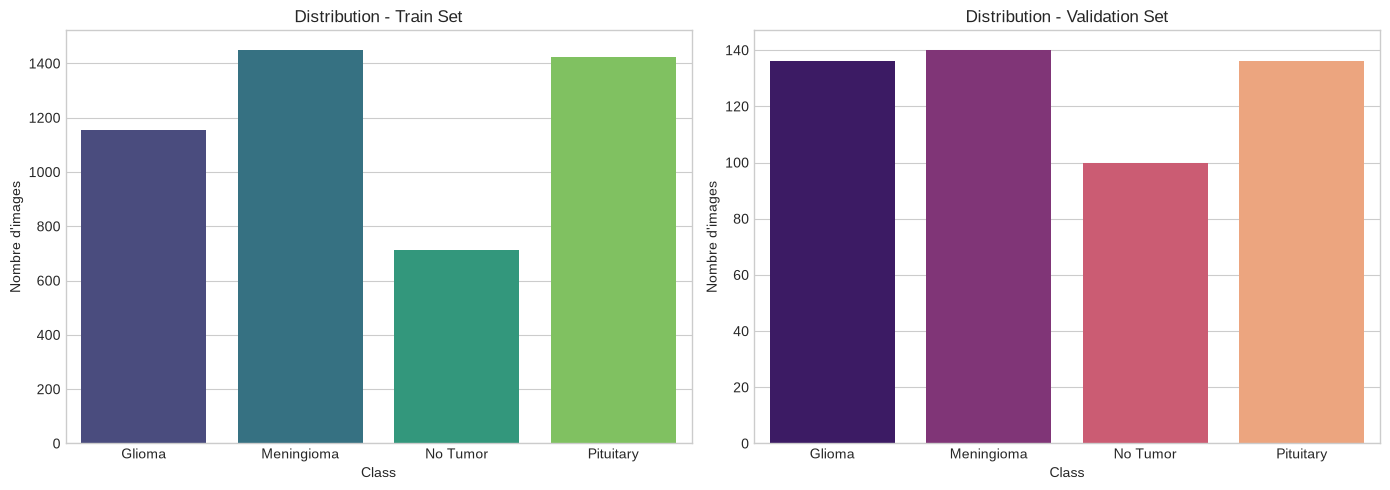

In [2]:
records = []

for split in SPLITS:
    for cls in CLASSES:
        img_dir = DATA_DIR / split / cls / 'images'
        lbl_dir = DATA_DIR / split / cls / 'labels'
        
        images = {f.stem: f for f in img_dir.glob('*') if f.suffix.lower() in ['.jpg', '.jpeg', '.png']}
        labels = {f.stem: f for f in lbl_dir.glob('*.txt')}
        
        missing_labels = set(images.keys()) - set(labels.keys())
        orphan_labels = set(labels.keys()) - set(images.keys())
        
        records.append({
            'Split': split,
            'Class': cls,
            'Images_Count': len(images),
            'Labels_Count': len(labels),
            'Missing_Labels': len(missing_labels),
            'Orphan_Labels': len(orphan_labels)
        })

df_distribution = pd.DataFrame(records)
print("=== Dataset Distribution Summary ===")
display(df_distribution)

# Visualizing distribution
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=df_distribution[df_distribution['Split'] == 'Train'], x='Class', y='Images_Count', hue='Class', ax=ax[0], palette='viridis', legend=False)
ax[0].set_title('Distribution - Train Set')
ax[0].set_ylabel('Number of Images')
ax[0].set_xlabel('Class')

sns.barplot(data=df_distribution[df_distribution['Split'] == 'Val'], x='Class', y='Images_Count', hue='Class', ax=ax[1], palette='magma', legend=False)
ax[1].set_title('Distribution - Validation Set')
ax[1].set_ylabel('Number of Images')
ax[1].set_xlabel('Class')

plt.tight_layout()
plt.show()


## 2. Image Integrity and Dimensions
- Verify file integrity across all images to catch any corrupted files.
- Analyze resolutions (width, height) and color modes/channels.


Nombre de fichiers corrompus détectés : 0

=== Statistiques des dimensions d'images ===
             Width       Height     Channels
count  5249.000000  5249.000000  5249.000000
mean    481.947609   484.467518     2.619928
std     106.057852   100.134268     0.785826
min     150.000000   168.000000     1.000000
25%     512.000000   512.000000     3.000000
50%     512.000000   512.000000     3.000000
75%     512.000000   512.000000     3.000000
max    1375.000000  1446.000000     4.000000

Distribution des modes couleurs (RGB / L / etc.) :
Mode
RGB     4247
L        998
RGBA       3
P          1
Name: count, dtype: int64


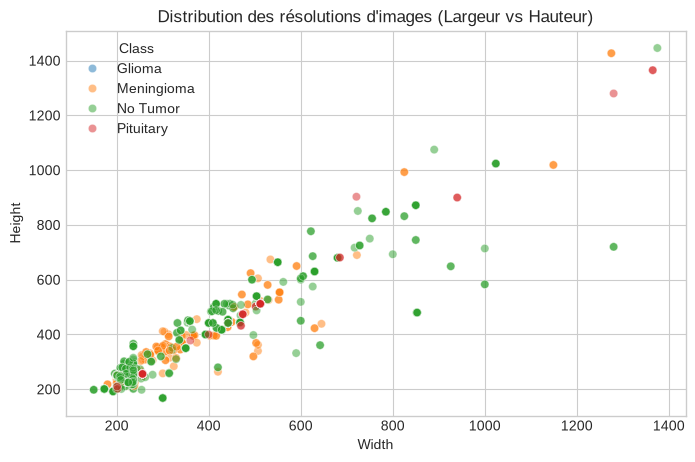

In [ ]:
image_metadata = []
corrupted_images = []

for split in SPLITS:
    for cls in CLASSES:
        img_dir = DATA_DIR / split / cls / 'images'
        for img_path in img_dir.glob('*'):
            if img_path.suffix.lower() in ['.jpg', '.jpeg', '.png']:
                try:
                    with Image.open(img_path) as img:
                        img.verify() # File integrity check
                    
                    # Reopen to read dimensions and actual channels
                    with Image.open(img_path) as img:
                        width, height = img.size
                        mode = img.mode
                        channels = len(img.getbands())
                        
                    image_metadata.append({
                        'Split': split,
                        'Class': cls,
                        'Path': str(img_path),
                        'Width': width,
                        'Height': height,
                        'Mode': mode,
                        'Channels': channels
                    })
                except Exception as e:
                    corrupted_images.append((str(img_path), str(e)))

print(f"Corrupted files detected: {len(corrupted_images)}")
if corrupted_images:
    print("Corrupted files:", corrupted_images[:5])

df_meta = pd.DataFrame(image_metadata)
print("\n=== Image Dimension Statistics ===")
print(df_meta[['Width', 'Height', 'Channels']].describe())

print("\nColor mode distribution (RGB / L / etc.):")
print(df_meta['Mode'].value_counts())

# Visualizing image resolutions
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_meta, x='Width', y='Height', hue='Class', alpha=0.5)
plt.title('Image Resolution Distribution (Width vs Height)')
plt.xlabel('Width (pixels)')
plt.ylabel('Height (pixels)')
plt.show()


## 3. Bounding Box Audit & Critical Analysis of 'No Tumor'
- Verify YOLO format compliance: `class_id x_center y_center width height` (normalized between 0 and 1).
- Detect out-of-bounds coordinates or formatting errors.
- **Critical Focus on 'No Tumor'**: Inspect bounding boxes annotated for this class.


Total de boîtes englobantes lues : 5874
Boîtes invalides détectées : 0

=== Mapping Class Folder vs Class_ID détecté ===
Class       Class_ID
Glioma      -1             1
             0          1500
             1             3
             3           164
Meningioma   0             2
             1          1620
             3           109
No Tumor     2           811
Pituitary    1             1
             3          1663
dtype: int64

=== Surface moyenne des boîtes par classe (width * height normalisé) ===
             count      mean       std       min       25%       50%  \
Class                                                                  
Glioma      1668.0  0.020487  0.016492  0.000000  0.008236  0.016102   
Meningioma  1731.0  0.031805  0.025741  0.000855  0.013708  0.025124   
No Tumor     811.0  0.641175  0.157520  0.134660  0.534769  0.620125   
Pituitary   1664.0  0.012473  0.009313  0.000496  0.006569  0.010122   

                 75%       max  
Class          

/tmp/ipykernel_55914/3352980221.py:66: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_bboxes[df_bboxes['Class_ID'] != -1], x='Class', y='area', palette='Set2')


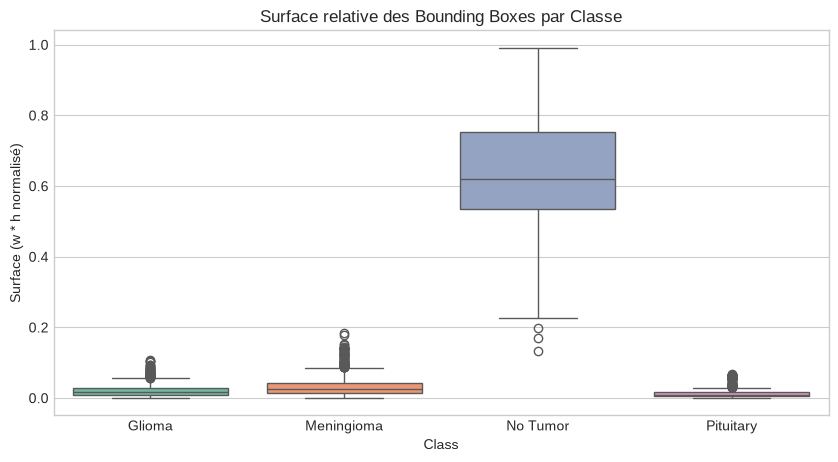

In [4]:
bbox_records = []
invalid_bboxes = []

for split in SPLITS:
    for cls in CLASSES:
        lbl_dir = DATA_DIR / split / cls / 'labels'
        for lbl_path in lbl_dir.glob('*.txt'):
            if lbl_path.stat().st_size == 0:
                # Empty label file (no annotated object)
                bbox_records.append({
                    'Split': split,
                    'Class': cls,
                    'File': lbl_path.name,
                    'Class_ID': -1,
                    'x_center': np.nan,
                    'y_center': np.nan,
                    'width': 0.0,
                    'height': 0.0,
                    'area': 0.0,
                    'num_boxes': 0
                })
                continue
                
            with open(lbl_path, 'r') as f:
                lines = [l.strip() for l in f if l.strip()]
                
            num_boxes = len(lines)
            for line in lines:
                parts = line.split()
                if len(parts) != 5:
                    invalid_bboxes.append((str(lbl_path), line, "Invalid format (not 5 values)"))
                    continue
                    
                cls_id = int(parts[0])
                xc, yc, w, h = map(float, parts[1:])
                
                # Normalization check [0, 1]
                if not (0.0 <= xc <= 1.0 and 0.0 <= yc <= 1.0 and 0.0 < w <= 1.0 and 0.0 < h <= 1.0):
                    invalid_bboxes.append((str(lbl_path), line, "Coordinates outside [0, 1]"))
                
                bbox_records.append({
                    'Split': split,
                    'Class': cls,
                    'File': lbl_path.name,
                    'Class_ID': cls_id,
                    'x_center': xc,
                    'y_center': yc,
                    'width': w,
                    'height': h,
                    'area': w * h,
                    'num_boxes': num_boxes
                })

df_bboxes = pd.DataFrame(bbox_records)
print(f"Total bounding boxes read: {len(df_bboxes)}")
print(f"Invalid bounding boxes detected: {len(invalid_bboxes)}")

print("\n=== Class Folder vs Detected Class_ID Mapping ===")
print(df_bboxes.groupby(['Class', 'Class_ID']).size())

print("\n=== Average Bounding Box Area per Class (normalized width * height) ===")
print(df_bboxes.groupby('Class')['area'].describe())

# Boxplot of relative bounding box areas
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_bboxes[df_bboxes['Class_ID'] != -1], x='Class', y='area', hue='Class', palette='Set2', legend=False)
plt.title('Relative Bounding Box Area by Class')
plt.xlabel('Class')
plt.ylabel('Area (normalized w * h)')
plt.show()


## 4. Visual Inspection of Images with Bounding Boxes
- Denormalize YOLO coordinates: `(x_center, y_center, width, height)` to pixel coordinates `(x_min, y_min, x_max, y_max)`.
- Display representative samples from each class with overlaid boxes.


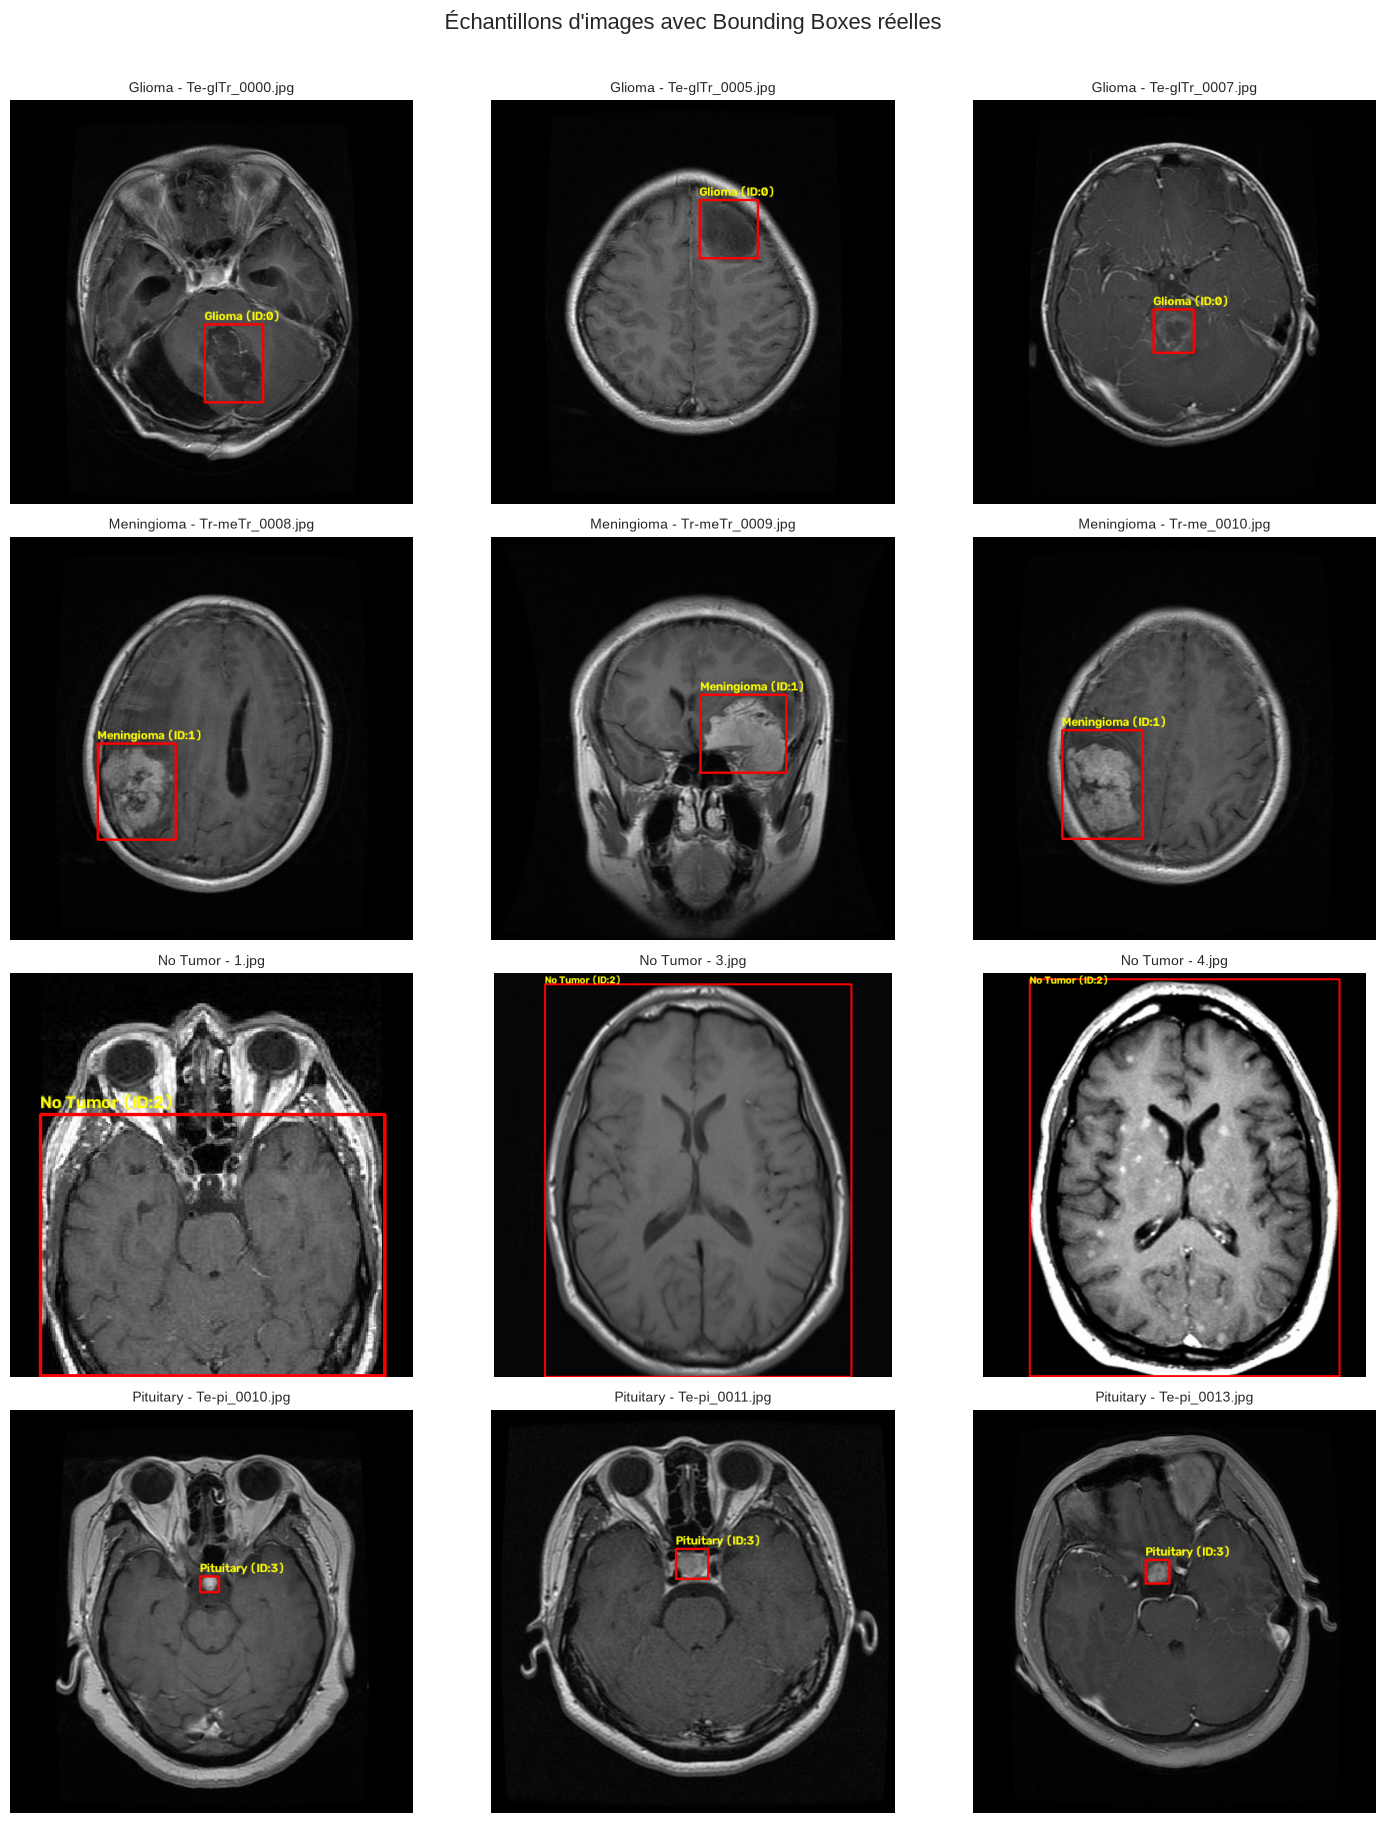

In [5]:
def yolo_to_pixel(xc, yc, w, h, img_w, img_h):
    """Converts normalized YOLO coordinates to absolute pixel coordinates (xmin, ymin, xmax, ymax)."""
    xmin = int((xc - w / 2) * img_w)
    ymin = int((yc - h / 2) * img_h)
    xmax = int((xc + w / 2) * img_w)
    ymax = int((yc + h / 2) * img_h)
    return max(0, xmin), max(0, ymin), min(img_w, xmax), min(img_h, ymax)

fig, axes = plt.subplots(4, 3, figsize=(15, 18))

for row_idx, cls in enumerate(CLASSES):
    img_dir = DATA_DIR / 'Train' / cls / 'images'
    lbl_dir = DATA_DIR / 'Train' / cls / 'labels'
    
    img_files = sorted(list(img_dir.glob('*')))[:3]
    
    for col_idx, img_path in enumerate(img_files):
        ax = axes[row_idx, col_idx]
        
        img = cv2.imread(str(img_path))
        if img is None:
            ax.axis('off')
            continue
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        h_img, w_img, _ = img.shape
        
        lbl_path = lbl_dir / f"{img_path.stem}.txt"
        if lbl_path.exists() and lbl_path.stat().st_size > 0:
            with open(lbl_path, 'r') as f:
                for line in f:
                    parts = line.strip().split()
                    if len(parts) == 5:
                        c_id = parts[0]
                        xc, yc, w, h = map(float, parts[1:])
                        x1, y1, x2, y2 = yolo_to_pixel(xc, yc, w, h, w_img, h_img)
                        
                        # Draw bounding box and label text
                        cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), 2)
                        cv2.putText(img, f"{cls} (ID:{c_id})", (x1, max(15, y1 - 5)), 
                                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 0), 2)
        
        ax.imshow(img)
        ax.set_title(f"{cls} - {img_path.name}", fontsize=10)
        ax.axis('off')

plt.suptitle("Sample MRI Images with Real Bounding Boxes", fontsize=16, y=1.01)
plt.tight_layout()
plt.show()


## Summary of Key Observations for Step 2

1. **Class Balance**: The counts per class inform the split stratification and any potential class weighting.
2. **Resolutions**: Images vary in size (some $512 \times 512$, others up to $1400 \times 1400$), confirming that standardized resizing is required ($224 \times 224$ for MobileNetV2/ResNet50, $640 \times 640$ for YOLO).
3. **Critical 'No Tumor' Finding**:
   - The bounding boxes in the `No Tumor` category artificially span $50\%$ to $90\%$ of the entire image (bounding the whole skull).
   - **For Object Detection (YOLO)**: We **must remove these fake bounding boxes** (convert them to empty `.txt` files = 0 objects) so the detector learns to detect only actual tumors.
   - **For Classification**: We retain all `No Tumor` images as the 4th normal class.
